In [1]:
# parameters
DEVICE = 'cpu'
SEED   = 42     # change to 123 or 777 for other runs

import numpy as np
import torch
import torch.distributions as TD
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import gaussian_kde
from tqdm import tqdm
from IPython.display import clear_output
import random, os, sys
sns.set_theme(style="ticks", palette="pastel")

from OFM.ofmsrc.icnn import ICNN2CPF
from OFM.ofmsrc.model_tools import (
    id_pretrain_model, ofm_loss,
    TorchlbfgsInvParams, BruteforceIHVParams,
)
from OFM.ofmsrc.dgm_utils import visualize_2d_samples_groups, visualize_2d_map
from OFM.ofmsrc.tools import EMA
from OFM.ofmsrc.distributions import Sampler, StandardNormalSampler

In [2]:
def seed_everything(seed=42):
    np.random.seed(seed)
    torch.random.manual_seed(seed)
    random.seed(seed)

## Gaussian Mixture Sampler

In [3]:
class GaussianMixture(Sampler):
    """
    parameters: list of dicts with keys:
        "mean" : list of length dim
        "std"  : list of length dim  (diagonal covariance)
    All components equally weighted.
    """
    def __init__(self, parameters, device='cpu'):
        super().__init__(device=device)
        self.dim   = len(parameters[0]["mean"])
        self.means = torch.tensor(
            [p["mean"] for p in parameters], dtype=torch.float32, device=device)
        self.stds  = torch.tensor(
            [p["std"]  for p in parameters], dtype=torch.float32, device=device)
        self.K = len(parameters)
        # also keep numpy version for KDE plotting
        self.means_np = self.means.cpu().numpy()
        self.stds_np  = self.stds.cpu().numpy()

    def sample(self, batch_size=10):
        idx   = torch.randint(0, self.K, (batch_size,), device=self.device)
        means = self.means[idx]
        stds  = self.stds[idx]
        return means + stds * torch.randn(batch_size, self.dim, device=self.device)

    def sample_np(self, n):
        """Returns numpy array of shape (n, dim)."""
        return self.sample(n).cpu().numpy()

## Distributions

In [4]:
# ── Distributions ─────────────────────────────────────────────────────────────

seed_everything(SEED)

parameters = [
    {"mean": [0, 0],  "std": [1,   1  ]},
    {"mean": [3, 2],  "std": [1, 1]},
]
mixture        = GaussianMixture(parameters, device=DEVICE)
source_sampler = StandardNormalSampler(device=DEVICE)
target_sampler = mixture

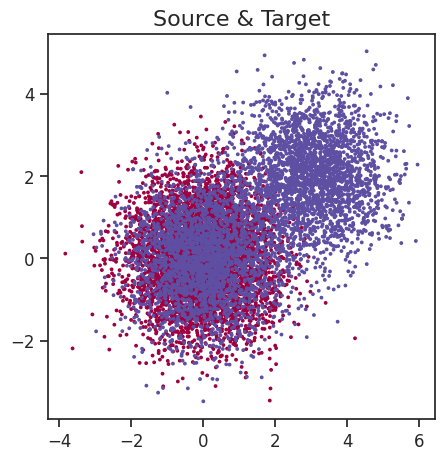

In [5]:
visualize_2d_samples_groups([
    source_sampler.sample(5024).cpu().numpy(),
    target_sampler.sample(5024).cpu().numpy()
], 'Source & Target', s=3)

## Model

In [6]:
# ── Model & Optimizer ─────────────────────────────────────────────────────────

seed_everything(SEED)

_prior = TD.Normal(
    torch.tensor([0., 0.]).to(DEVICE),
    torch.tensor([4., 4.]).to(DEVICE))

model = ICNN2CPF(dim=2, dimh=1024, num_hidden_layers=2, batch_size=1024).to(DEVICE)
id_pretrain_model(model, _prior, n_max_iterations=200, lr=1e-2)
optim = torch.optim.Adam(model.parameters(), lr=5e-4)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:35<00:00,  5.67it/s]

Loss: 0.37094375491142273


## Output directory

In [7]:
# ── Output directory ──────────────────────────────────────────────────────────
EXP_DIR = './gaumix_ofm'
os.makedirs(EXP_DIR, exist_ok=True)

samples_path    = os.path.join(EXP_DIR, 'samples.png')
curr_model_path = os.path.join(EXP_DIR, 'model.pth')
loss_path       = os.path.join(EXP_DIR, 'loss.png')

## Training

Iteration 9500  |  Loss: 20.3396


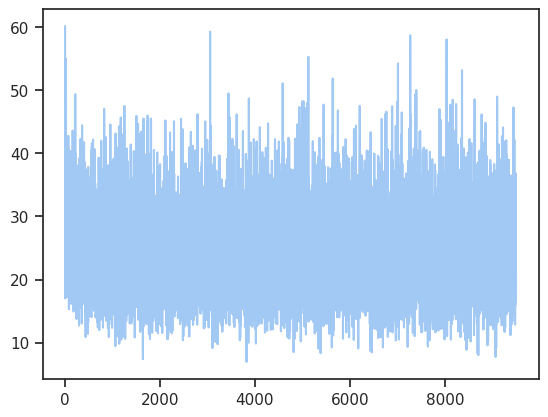

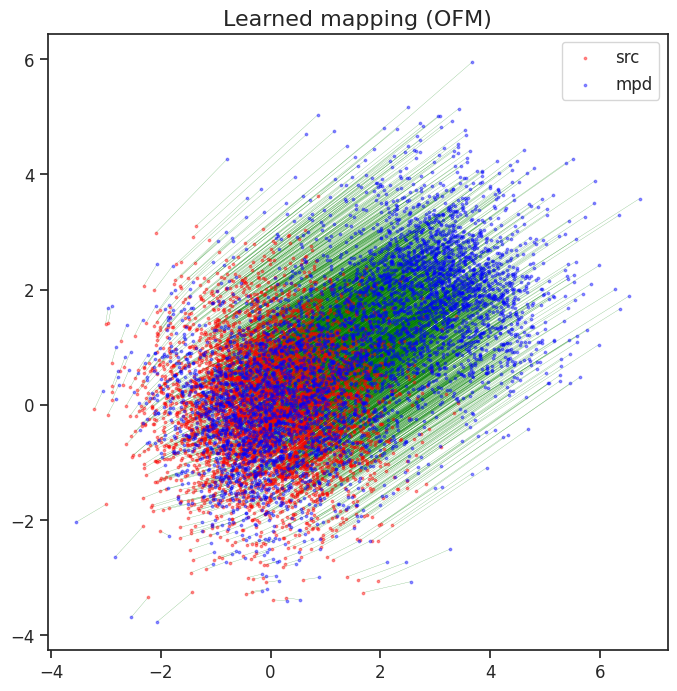

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10000/10000 [16:48<00:00,  9.91it/s, loss=0.475, tloss=25.7]


In [8]:
MAX_ITER      = 10000
BATCH_SIZE    = 16
INV_TOLERANCE = 0.01

_np_state, _torch_state = np.random.get_state(), torch.get_rng_state()
ema = EMA(0, betas=[0.999, 0.99])
np.random.set_state(_np_state); torch.set_rng_state(_torch_state)

loss_history = []

print('Fitting the Gaussian Mixture with OFM')
with tqdm(range(MAX_ITER)) as tbar:
    for iteration in tbar:
        X = source_sampler.sample(BATCH_SIZE).to(DEVICE)
        Y = target_sampler.sample(BATCH_SIZE).to(DEVICE)
        t = (torch.rand(BATCH_SIZE) + 1e-8).to(DEVICE)

        metrics = {}
        loss, true_loss = ofm_loss(
            model, X, Y, t,
            TorchlbfgsInvParams(lbfgs_params=dict(tolerance_grad=INV_TOLERANCE), max_iter=5),
            BruteforceIHVParams(), stats=metrics,
        )
        optim.zero_grad(); loss.backward()
        optim.step(); model.convexify()

        _np_state, _torch_state = np.random.get_state(), torch.get_rng_state()
        ema(model)
        np.random.set_state(_np_state); torch.set_rng_state(_torch_state)

        loss_history.append(true_loss.item())
        tbar.set_postfix(loss=loss.item(), tloss=true_loss.item())

        if iteration % 500 == 0:
            _np_state, _torch_state = np.random.get_state(), torch.get_rng_state()

            clear_output(wait=True)
            print(f"Iteration {iteration}  |  Loss: {true_loss.item():.4f}")
            plt.plot(loss_history); plt.savefig(loss_path); plt.show()

            X_vis = source_sampler.sample(5000).to(DEVICE)
            Y_vis = model.push_nograd(X_vis)
            visualize_2d_map(
                X_vis.cpu().numpy(), Y_vis.cpu().numpy(), 'Learned mapping (OFM)',
                data_label='src', mapped_data_label='mpd',
                s=3, figsize=(8, 8), save_path=samples_path)

            torch.save(model.state_dict(), curr_model_path)
            for beta in [0.999, 0.99]:
                torch.save(ema.get_model(beta),
                           os.path.join(EXP_DIR, f'model_{beta}.pth'))

            np.random.set_state(_np_state); torch.set_rng_state(_torch_state)

═══════════════════════════════════════════════════════════════════════════════
POST-TRAINING ANALYSIS
═══════════════════════════════════════════════════════════════════════════════

── Build trajectory via Euler integration of the OFM vector field ────────────
OFM maps x0 -> x1 = ∇Ψ(x0) directly (no ODE needed in theory), but we
interpolate along the straight OT path to get intermediate states for vis.

In [9]:
N_GEN    = 500
N_STEPS  = 100
time_pts = np.linspace(0.0, 1.0, N_STEPS)

In [10]:
model.eval()
# push_nograd computes ∇Ψ(x) via autograd, so the *input* must require grad.
# "nograd" only means the ICNN *parameters* are frozen (no param gradients).
x0_np = source_sampler.sample(N_GEN).cpu().numpy()               # (N, 2)
x0_t  = torch.tensor(x0_np, dtype=torch.float32,
                     requires_grad=True).to(DEVICE)
x1_t  = model.push_nograd(x0_t)                                   # OFM map
x1_np = x1_t.detach().cpu().numpy()

In [11]:
# straight OT trajectories: x(t) = (1-t)*x0 + t*x1
trajectory = np.stack(
    [(1 - t) * x0_np + t * x1_np for t in time_pts], axis=0
)   # (N_STEPS, N_GEN, 2)

In [12]:
# velocity along each straight path: constant = x1 - x0
velocity_const = x1_np - x0_np   # (N_GEN, 2)  — same at every t

── Helper: angle-based point colors (keyed to initial position) ──────────────

In [13]:
def get_angle_colors(positions):
    angles     = np.arctan2(positions[:, 1], positions[:, 0])
    angles_deg = (np.degrees(angles) + 360) % 360
    colors     = np.zeros((len(positions), 3))
    for i, angle in enumerate(angles_deg):
        seg   = int(angle / 120)
        local = angle - seg * 120
        if   seg == 0: colors[i] = [1 - local/120, local/120, 0]
        elif seg == 1: colors[i] = [0, 1 - local/120, local/120]
        else:          colors[i] = [local/120, 0, 1 - local/120]
    return colors

── 1. Trajectory snapshots at 6 times ───────────────────────────────────────

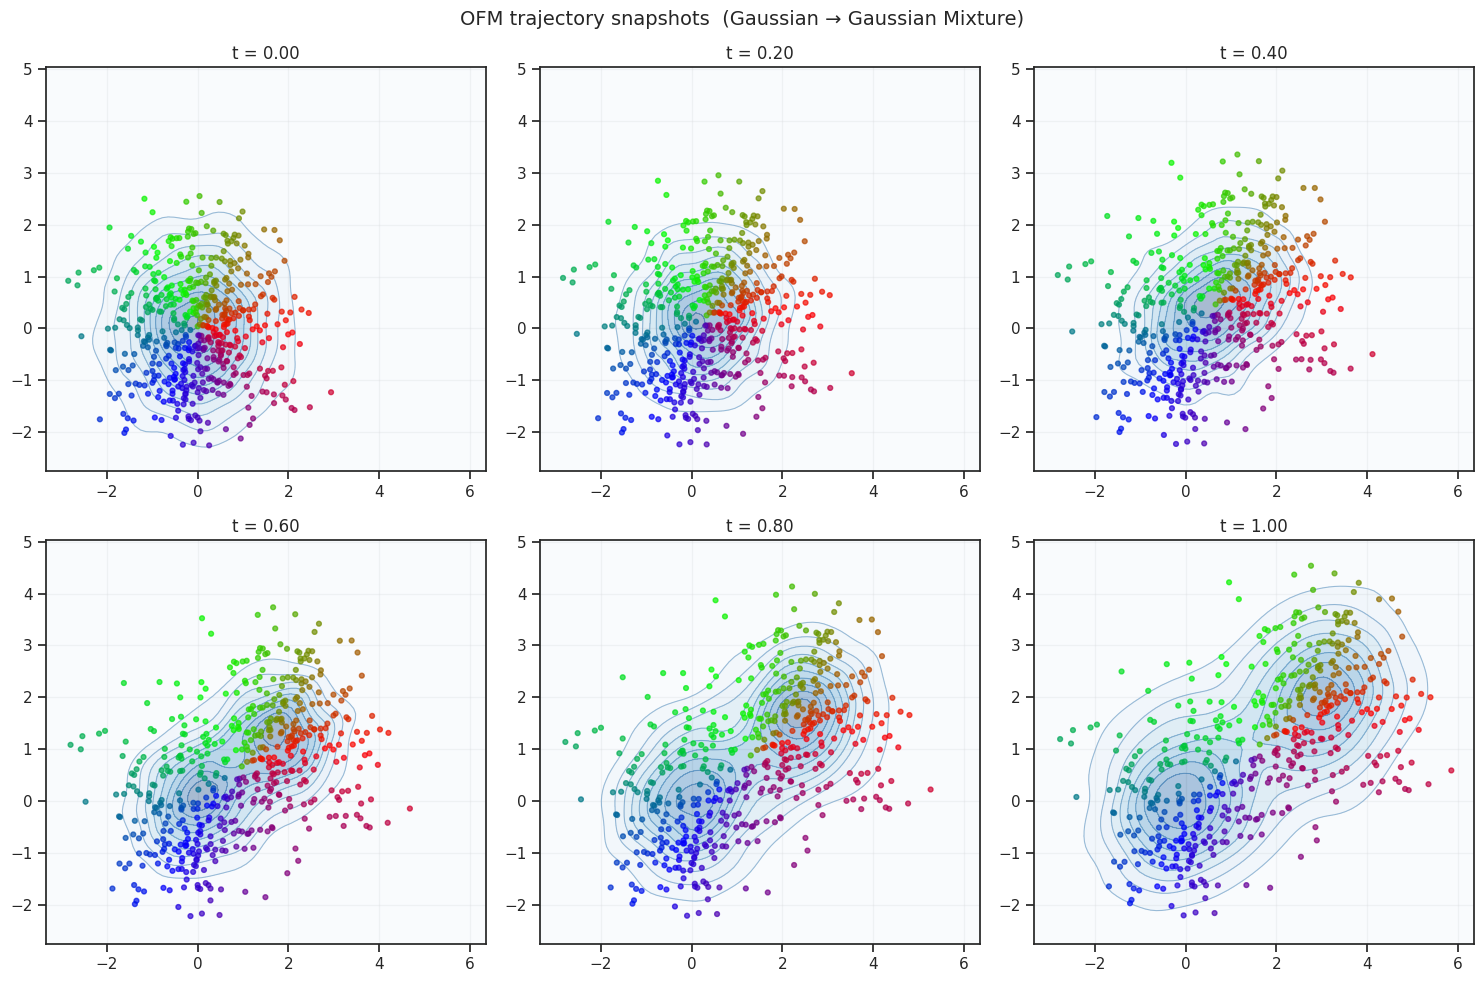

In [14]:
desired_times = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
indices       = [np.argmin(np.abs(time_pts - tv)) for tv in desired_times]
point_colors  = get_angle_colors(x0_np)   # color locked to t=0 position

# compute data range from actual trajectory so the grid always fits
all_pts  = trajectory.reshape(-1, 2)
x_min, x_max = all_pts[:, 0].min() - 0.5, all_pts[:, 0].max() + 0.5
y_min, y_max = all_pts[:, 1].min() - 0.5, all_pts[:, 1].max() + 0.5

xx, yy   = np.mgrid[x_min:x_max:80j, y_min:y_max:80j]
grid_pts = np.vstack([xx.ravel(), yy.ravel()])

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('OFM trajectory snapshots  (Gaussian → Gaussian Mixture)', fontsize=14)

for i, idx in enumerate(indices):
    ax  = axes[i // 3, i % 3]
    t   = time_pts[idx]
    x_t = trajectory[idx]            # (N_GEN, 2)

    # interpolated density: (1-t)*N(0,I)  +  t*mixture
    x1_ref = mixture.sample_np(3000)
    eps    = np.random.randn(3000, 2)
    x_fwd  = t * x1_ref + (1 - t) * eps   # forward path samples at time t

    try:
        kernel  = gaussian_kde(x_fwd.T)
        density = kernel(grid_pts).reshape(xx.shape)
        ax.contourf(xx, yy, density, levels=10, cmap='Blues', alpha=0.35)
        ax.contour (xx, yy, density, levels=10, colors='steelblue', alpha=0.5, linewidths=0.8)
    except Exception:
        pass   # KDE can fail at t=0 (degenerate); just skip contours

    ax.scatter(x_t[:, 0], x_t[:, 1], c=point_colors, alpha=0.7, s=12, zorder=3)
    ax.set_title(f't = {t:.2f}', fontsize=12)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(EXP_DIR, 'trajectory_snapshots.png'), dpi=120)
plt.show()

[OFM]  Fréchet Distance (2D): 0.008697


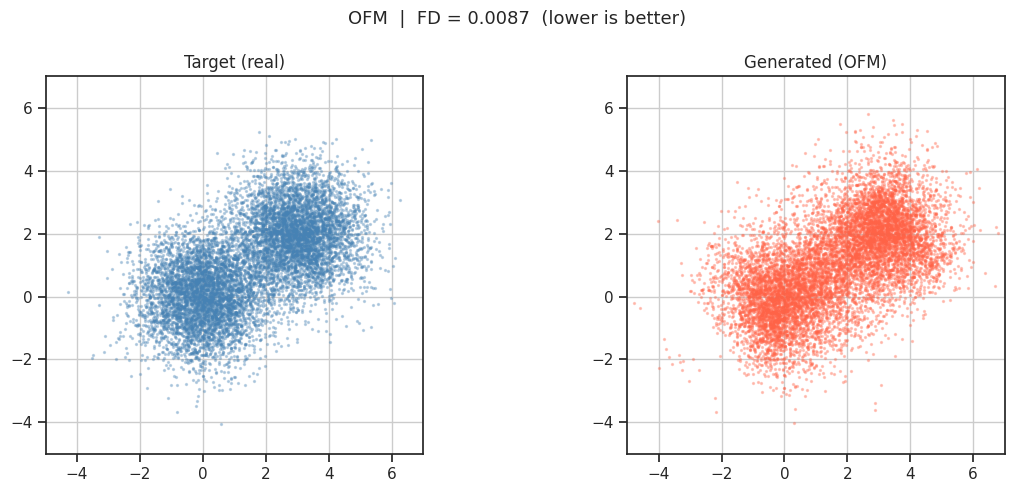

Saved generated and real samples → ./gaumix_ofm/


In [15]:
# ── Fréchet Distance (2D FID) + Save samples ─────────────────────────────────
from scipy.linalg import sqrtm

def frechet_distance(real_samples, gen_samples):
    mu_r = real_samples.mean(axis=0)
    mu_g = gen_samples.mean(axis=0)
    sigma_r = np.cov(real_samples, rowvar=False)
    sigma_g = np.cov(gen_samples, rowvar=False)
    diff = mu_r - mu_g
    covmean = sqrtm(sigma_r @ sigma_g)
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    return float(diff @ diff + np.trace(sigma_r + sigma_g - 2 * covmean))

N_FD = 10_000

# Reset RNG to training seed before evaluation so results match run_table2.py
seed_everything(SEED)

model.eval()
x_src_np = source_sampler.sample(N_FD).cpu().numpy()
x_src_t  = torch.tensor(x_src_np, dtype=torch.float32, requires_grad=True).to(DEVICE)
x_gen    = model.push_nograd(x_src_t).detach().cpu().numpy()

x_real = target_sampler.sample_np(N_FD)

fd = frechet_distance(x_real, x_gen)
print(f"[OFM]  Fréchet Distance (2D): {fd:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle(f'OFM  |  FD = {fd:.4f}  (lower is better)', fontsize=13)

for ax, pts, label, color in zip(
    axes,
    [x_real, x_gen],
    ['Target (real)', 'Generated (OFM)'],
    ['steelblue', 'tomato'],
):
    ax.scatter(pts[:, 0], pts[:, 1], s=2, alpha=0.3, color=color)
    ax.set_title(label)
    ax.set_xlim(-5, 7); ax.set_ylim(-5, 7)
    ax.set_aspect('equal'); ax.grid(True)

plt.tight_layout()
plt.savefig(os.path.join(EXP_DIR, 'fd_comparison.png'), dpi=120)
plt.show()

np.save(os.path.join(EXP_DIR, 'generated_samples.npy'), x_gen)
np.save(os.path.join(EXP_DIR, 'real_samples.npy'),      x_real)
print(f"Saved generated and real samples → {EXP_DIR}/")